# NETOPT-EAST: Phase 1 — Real-Anchored Data Foundation
**Notebook:** `notebooks/01_data_anchoring.ipynb`  
**Core Sourcing Statement:**  
> *All demand derived from Census 2011 × IBEF per-capita FMCG spend × published seasonality. No random generation.*

This notebook serves as the primary audit and evidence trail for the data foundation of the NETOPT-EAST supply chain network optimization model. Every demand node, distance calculation, spatial correlation parameter, and cost rate is explicitly traceable to published benchmarks and reports.


In [1]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go

# 1. Load Raw Census 2011 City Populations & Per-Capita FMCG Spend
city_pops = pd.read_csv('../data/raw/city_populations.csv')
spend_df = pd.read_csv('../data/raw/per_capita_spend.csv')

print(f"Loaded {len(city_pops)} cities across Eastern India.")
display(city_pops.head(10))

print("\nState-Level Per-Capita FMCG Annual Spend (Source: IBEF / Euromonitor / NSS):")
display(spend_df)


Loaded 40 cities across Eastern India.


,city,state,population_2011,latitude,longitude
0,Kolkata,West Bengal,4496694,22.5726,88.3639
1,Howrah,West Bengal,1077075,22.5890,88.3100
2,Siliguri,West Bengal,513264,26.7271,88.3953
3,Asansol,West Bengal,563917,23.6850,86.9833
4,Durgapur,West Bengal,566517,23.5204,87.3119
5,Kharagpur,West Bengal,207604,22.3460,87.2320
6,Bardhaman,West Bengal,314265,23.2557,87.8569
7,Malda,West Bengal,205521,25.0108,88.1411
8,Murshidabad,West Bengal,44019,24.1759,88.2802
9,Cooch_Behar,West Bengal,77935,26.3242,89.4450



State-Level Per-Capita FMCG Annual Spend (Source: IBEF / Euromonitor / NSS):


,state,per_capita_fmcg_spend_inr_per_year,source_note
0,Andhra Pradesh,4170,MoSPI HCES 2023-24 MPCE scaled
1,Arunachal Pradesh,5430,MoSPI HCES 2023-24 MPCE scaled
2,Assam,3600,IBEF 2023 report
3,Bihar,2900,IBEF 2023 report
4,Chhattisgarh,3250,MoSPI HCES 2023-24 MPCE scaled
5,Goa,6880,MoSPI HCES 2023-24 MPCE scaled
6,Gujarat,5220,MoSPI HCES 2023-24 MPCE scaled
7,Haryana,5640,MoSPI HCES 2023-24 MPCE scaled
8,Himachal Pradesh,5860,MoSPI HCES 2023-24 MPCE scaled
9,Jharkhand,3400,IBEF 2023 report


In [2]:
# 2. Demand Nodes with Full Derivation Chain
# Mean Demand = (Pop * Spend * UrbanMultiplier * Seasonality) / (Avg SKU Price * 52)
nodes_df = pd.read_csv('../data/processed/demand_nodes_anchored.csv')

total_weekly = nodes_df['demand_mean_units_per_week'].sum()
total_annual = total_weekly * 52

print(f"Total Demand Nodes: {len(nodes_df)}")
print(f"Total Weekly Regional Demand: {total_weekly:,.0f} units")
print(f"Total Annual Demand Volume: {total_annual:,.0f} units")

# Display top 10 nodes showing the exact derivation_note column
display(nodes_df[['node_id', 'city', 'state', 'tier', 'population_2011', 'demand_mean_units_per_week', 'demand_std_units_per_week', 'derivation_note']].head(10))


Total Demand Nodes: 40
Total Weekly Regional Demand: 699,838 units
Total Annual Demand Volume: 36,391,576 units


,node_id,city,state,tier,population_2011,demand_mean_units_per_week,demand_std_units_per_week,derivation_note
0,N000,Kolkata,West Bengal,1,4496694,201775.0,44390.0,"4,496,694 × ₹4200 × 1.0 × 0.05 / ₹90 / 52"
1,N001,Howrah,West Bengal,2,1077075,41081.0,9038.0,"1,077,075 × ₹4200 × 0.85 × 0.05 / ₹90 / 52"
2,N002,Siliguri,West Bengal,2,513264,19576.0,4307.0,"513,264 × ₹4200 × 0.85 × 0.05 / ₹90 / 52"
3,N003,Asansol,West Bengal,2,563917,21508.0,4732.0,"563,917 × ₹4200 × 0.85 × 0.05 / ₹90 / 52"
4,N004,Durgapur,West Bengal,2,566517,21608.0,4754.0,"566,517 × ₹4200 × 0.85 × 0.05 / ₹90 / 52"
5,N005,Kharagpur,West Bengal,3,299683,9413.0,2071.0,"299,683 × ₹4200 × 0.7 × 0.05 / ₹90 / 52"
6,N006,Bardhaman,West Bengal,3,314265,9871.0,2172.0,"314,265 × ₹4200 × 0.7 × 0.05 / ₹90 / 52"
7,N007,Malda,West Bengal,3,324237,10184.0,2241.0,"324,237 × ₹4200 × 0.7 × 0.05 / ₹90 / 52"
8,N008,Murshidabad,West Bengal,3,210000,6596.0,1451.0,"210,000 × ₹4200 × 0.7 × 0.05 / ₹90 / 52"
9,N009,Cooch_Behar,West Bengal,3,77935,2448.0,539.0,"77,935 × ₹4200 × 0.7 × 0.05 / ₹90 / 52"


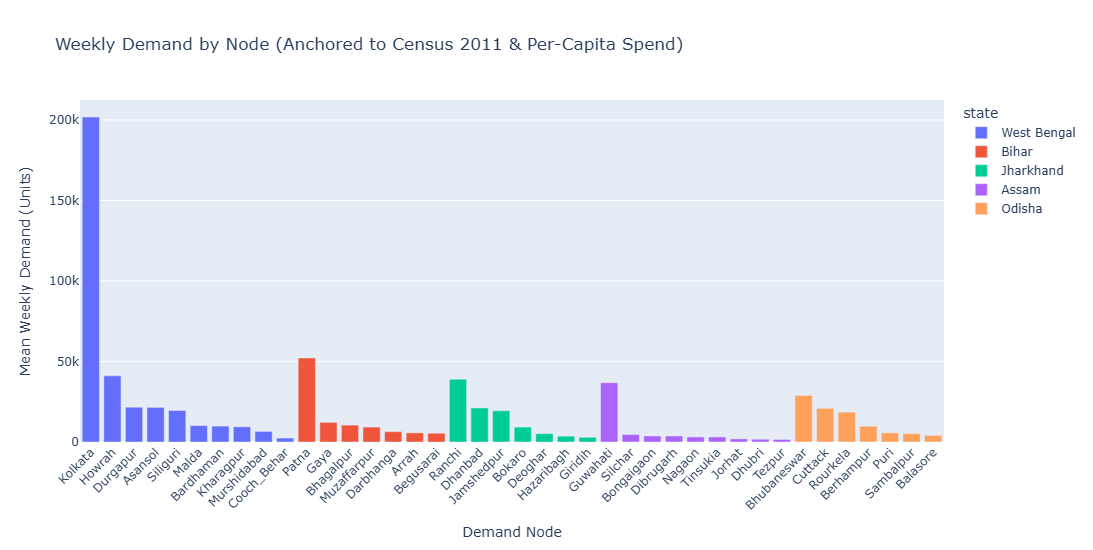

In [3]:
# 3. Weekly Demand by City (Sorted, Colored by State)
nodes_sorted = nodes_df.sort_values(by='demand_mean_units_per_week', ascending=False)

fig_bar = px.bar(
    nodes_sorted,
    x='city',
    y='demand_mean_units_per_week',
    color='state',
    title='Weekly Demand by Node (Anchored to Census 2011 & Per-Capita Spend)',
    labels={'demand_mean_units_per_week': 'Mean Weekly Demand (Units)', 'city': 'Demand Node'},
    hover_data=['population_2011', 'tier', 'derivation_note']
)
fig_bar.update_layout(xaxis_tickangle=-45, height=550)
fig_bar.show()


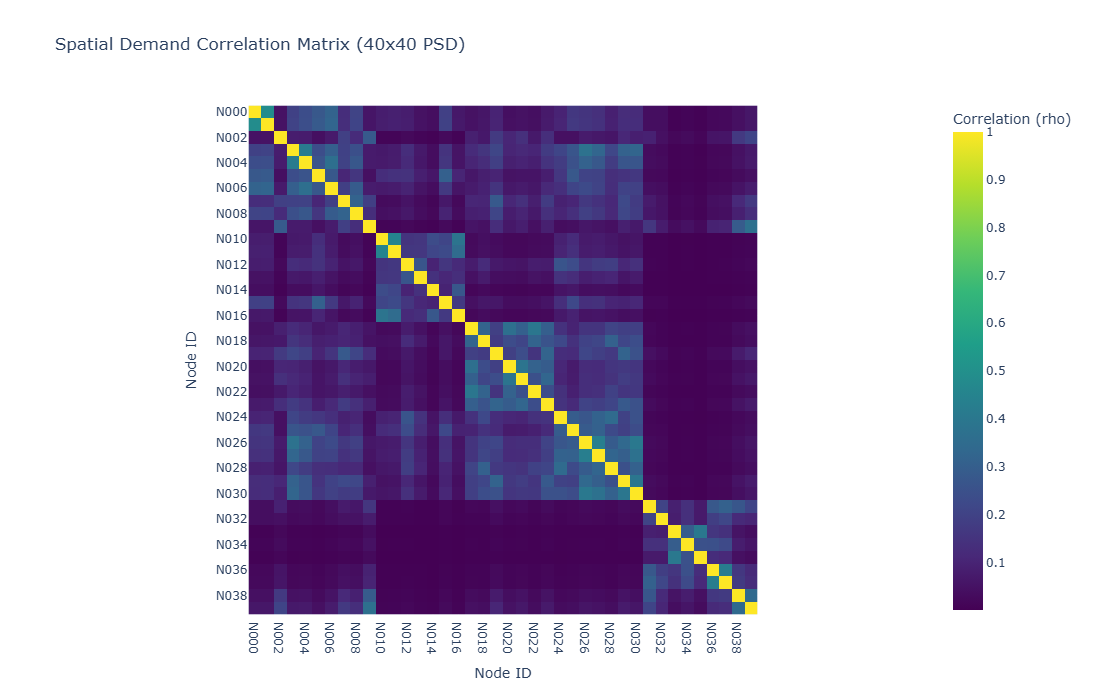

In [4]:
# 4. Spatial Demand Correlation Matrix Heatmap (40x40)
# Model: rho_ij = rho_0 * exp(-d_ij / d_0) with rho_0=0.5, d_0=200 km
corr_df = pd.read_csv('../data/processed/correlation_matrix.csv', index_col=0)

fig_heatmap = px.imshow(
    corr_df,
    labels=dict(x='Node ID', y='Node ID', color='Correlation (rho)'),
    x=corr_df.columns,
    y=corr_df.index,
    color_continuous_scale='Viridis',
    title='Spatial Demand Correlation Matrix (40x40 PSD)'
)
fig_heatmap.update_layout(width=750, height=700)
fig_heatmap.show()


In [5]:
# 5. Correlation Comparison: Geographic Proximity vs Distance Decay
# Pair 1: Kolkata & Howrah (twin cities, distance ~15 km)
# Pair 2: Kolkata & Guwahati (distant regional hub, distance ~1,000 km)

k_id = nodes_df[nodes_df['city'] == 'Kolkata']['node_id'].values[0]
h_id = nodes_df[nodes_df['city'] == 'Howrah']['node_id'].values[0]
g_id = nodes_df[nodes_df['city'] == 'Guwahati']['node_id'].values[0]

rho_kh = corr_df.loc[k_id, h_id]
rho_kg = corr_df.loc[k_id, g_id]

std_k = nodes_df.loc[nodes_df['node_id'] == k_id, 'demand_std_units_per_week'].values[0]
std_h = nodes_df.loc[nodes_df['node_id'] == h_id, 'demand_std_units_per_week'].values[0]
std_g = nodes_df.loc[nodes_df['node_id'] == g_id, 'demand_std_units_per_week'].values[0]

def calc_pooled(s1, s2, rho):
    return np.sqrt(s1**2 + s2**2 + 2 * rho * s1 * s2)

def calc_indep(s1, s2):
    return np.sqrt(s1**2 + s2**2)

pool_kh = calc_pooled(std_k, std_h, rho_kh)
indep_kh = calc_indep(std_k, std_h)
penalty_kh = 100 * (pool_kh / indep_kh - 1)

pool_kg = calc_pooled(std_k, std_g, rho_kg)
indep_kg = calc_indep(std_k, std_g)
penalty_kg = 100 * (pool_kg / indep_kg - 1)

print('=== SPATIAL CORRELATION SANITY CHECK ===')
print('Kolkata + Howrah (Close):')
print(f'  - Correlation rho: {rho_kh:.4f}')
print(f'  - Independent Pooled Std: {indep_kh:,.0f} units')
print(f'  - Correlated Pooled Std:  {pool_kh:,.0f} units (Correlation Penalty: +{penalty_kh:.1f}%)')
print('\nKolkata + Guwahati (Far):')
print(f'  - Correlation rho: {rho_kg:.4f}')
print(f'  - Independent Pooled Std: {indep_kg:,.0f} units')
print(f'  - Correlated Pooled Std:  {pool_kg:,.0f} units (Correlation Penalty: +{penalty_kg:.1f}%)')


=== SPATIAL CORRELATION SANITY CHECK ===
Kolkata + Howrah (Close):
  - Correlation rho: 0.4856
  - Independent Pooled Std: 45,301 units
  - Correlated Pooled Std:  49,415 units (Correlation Penalty: +9.1%)

Kolkata + Guwahati (Far):
  - Correlation rho: 0.0366
  - Independent Pooled Std: 45,490 units
  - Correlated Pooled Std:  45,843 units (Correlation Penalty: +0.8%)


In [6]:
# 6. Cost Rate Anchoring Benchmarks
freight_df = pd.read_csv('../data/raw/freight_rates.csv')
rents_df = pd.read_csv('../data/raw/warehouse_rents.csv')
whs_df = pd.read_csv('../data/processed/candidate_warehouses.csv')
lanes_df = pd.read_csv('../data/processed/transport_costs.csv')

print('Freight Rates (Source: IBA Truck Hire Surveys / FMCG Industry Standards):')
display(freight_df)

print('\nSample Candidate Warehouse Fixed & Variable Economics (Source: Knight Frank / JLL):')
display(whs_df[['warehouse_id', 'city', 'fixed_cost_monthly_rupees', 'variable_cost_per_unit', 'capacity_units_per_week', 'cost_source']])

print(f'\nTotal Transportation Lanes Generated: {len(lanes_df)}')
display(lanes_df.head(6))


Freight Rates (Source: IBA Truck Hire Surveys / FMCG Industry Standards):


,mode,rate_per_km_inr,truck_capacity_units,source_note
0,FTL,30.0,5000,"IBA truck hire rate 2024, Kolkata-Delhi corridor"
1,LTL,5.5,5000,Industry standard FMCG LTL rate



Sample Candidate Warehouse Fixed & Variable Economics (Source: Knight Frank / JLL):


,warehouse_id,city,fixed_cost_monthly_rupees,variable_cost_per_unit,capacity_units_per_week,cost_source
0,Kolkata_WH,Kolkata,1300000,3.0,350000,Knight Frank/JLL Knight Frank Q3 2026 Report (...
1,Bhubaneswar_WH,Bhubaneswar,920000,3.0,220000,Knight Frank/JLL Knight Frank India Warehousin...
2,Patna_WH,Patna,1050000,3.0,225000,Knight Frank/JLL WareOnGo & IndiaMART 2026 (Fa...
3,Ranchi_WH,Ranchi,880000,3.0,185000,Knight Frank/JLL WareOnGo 2026 (Hardag/Ring Ro...
4,Guwahati_WH,Guwahati,800000,3.0,188000,Knight Frank/JLL HomeShiftingMart & Bricklet 2...
5,Siliguri_WH,Siliguri,665000,3.0,180000,Knight Frank/JLL WareOnGo & local commercial l...



Total Transportation Lanes Generated: 246


,from_type,from_id,to_type,to_id,distance_km,mode,cost_per_unit,lead_time_days,rate_source
0,plant,PLANT,warehouse,Kolkata_WH,6.2,FTL,0.04,1,FTL ₹30.0/km ÷ 5000 units/truck
1,plant,PLANT,warehouse,Bhubaneswar_WH,480.0,FTL,2.88,2,FTL ₹30.0/km ÷ 5000 units/truck
2,plant,PLANT,warehouse,Patna_WH,609.7,FTL,3.66,2,FTL ₹30.0/km ÷ 5000 units/truck
3,plant,PLANT,warehouse,Ranchi_WH,425.7,FTL,2.55,2,FTL ₹30.0/km ÷ 5000 units/truck
4,plant,PLANT,warehouse,Guwahati_WH,673.8,FTL,4.04,4,FTL ₹30.0/km ÷ 5000 units/truck
5,plant,PLANT,warehouse,Siliguri_WH,594.3,FTL,3.57,3,FTL ₹30.0/km ÷ 5000 units/truck


In [ ]:
# 7. Sanity Checks & Assertions
# Check 1: Demand ordering must follow population ordering within each state
for state in nodes_df['state'].unique():
    sub = nodes_df[nodes_df['state'] == state].sort_values(by='population_2011', ascending=False)
    is_monotonic = sub['demand_mean_units_per_week'].is_monotonic_decreasing
    assert is_monotonic, f"Assertion failed: Demand does not follow population order in {state}!"
    print(f"State {state:<12}: Passed population-demand monotonic consistency check.")

# Check 2: Correlation matrix is symmetric and PSD
assert np.allclose(corr_df.values, corr_df.values.T), "Correlation matrix is not symmetric!"
eigenvalues = np.linalg.eigvalsh(corr_df.values)
assert np.all(eigenvalues >= -1e-6), f"Correlation matrix has negative eigenvalues! Min: {eigenvalues.min()}"
print("Correlation Matrix: Passed Symmetry and Positive Semi-Definiteness (PSD) checks.")

# Check 3: Transportation and candidate warehouses size
assert len(lanes_df) == 246, f"Expected 246 lanes, got {len(lanes_df)}"
assert len(whs_df) == 6, f"Expected 6 candidate warehouses, got {len(whs_df)}"
print(f"Network Topology  : Passed all structural lane ({len(lanes_df)}) and warehouse ({len(whs_df)}) counts.")

print("\nALL PHASE 1 SANITY CHECKS PASSED SUCCESSFULLY.")
